Choose Input Mode:
1. Default Values
2. Custom Values


Enter your choice (1 or 2):  1



TEXT-BASED DP TABLE

DP Table Construction:
       0   1   2   3   4   5   6   7
    ------------------------------------
R0:   0   0   0   0   0   0   0   0
R1:   0   1   1   1   1   1   1   1
R2:   0   1   1   4   5   5   5   5
R3:   0   1   1   4   5   6   6   9
R4:   0   1   1   4   5   7   8   9

Maximum Achievable Profit: 9
Selected Item Indices: [1, 2]

COMPLEXITY STATISTICS
Maximum Achievable Profit: 9
Selected Item Indices: [1, 2]

-------------------------------------------------------
 COMPREHENSIVE COMPLEXITY STATISTICS
-------------------------------------------------------
Measured Execution Time  : 0.00002630 seconds
Calculated Space Usage   : 720 bytes
Total Subproblems Solved : 28

Visualizations...


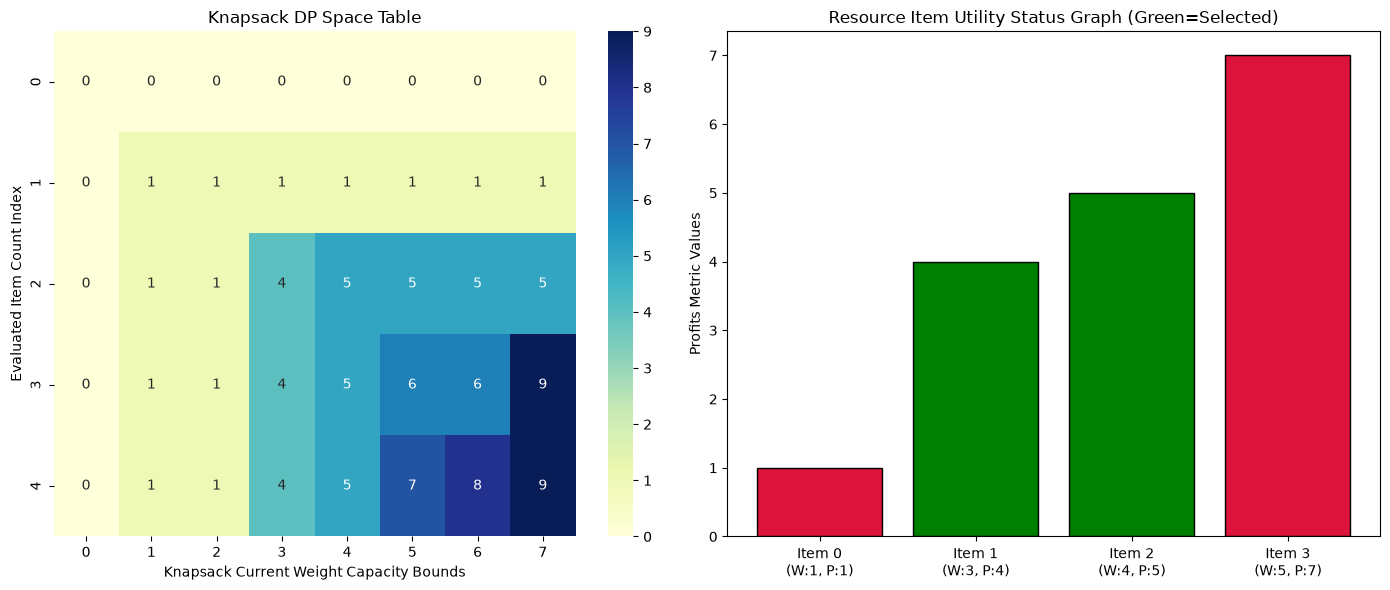

In [4]:
import sys
import time
import matplotlib.pyplot as plt
import seaborn as sns

def allocate_resources_v1(weights, profits, capacity):
    n = len(weights)
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        for w in range(1, capacity + 1):
            if weights[i - 1] <= w:
                dp[i][w] = max(
                    profits[i - 1] + dp[i - 1][w - weights[i - 1]], dp[i - 1][w]
                )
            else:
                dp[i][w] = dp[i - 1][w]

    selected_items = []
    w = capacity
    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            selected_items.append(i - 1)
            w -= weights[i - 1]
    selected_items.reverse()

    print("\n" + "=" * 55)
    print("TEXT-BASED DP TABLE")
    print("=" * 55)
    print("\nDP Table Construction:")
    header = "     " + " ".join(f"{j:3d}" for j in range(capacity + 1))
    print(header)
    print("    " + "-" * len(header))
    for i in range(n + 1):
        row_label = f"R{i}:"
        row_vals = " ".join(f"{dp[i][j]:3d}" for j in range(capacity + 1))
        print(f"{row_label} {row_vals}")

    print(f"\nMaximum Achievable Profit: {dp[n][capacity]}")
    print(f"Selected Item Indices: {selected_items}")


def allocate_resources_v2(weights, profits, capacity):
    n = len(weights)
    subproblems = 0

    start_time = time.perf_counter()
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        for w in range(1, capacity + 1):
            subproblems += 1
            if weights[i - 1] <= w:
                dp[i][w] = max(
                    profits[i - 1] + dp[i - 1][w - weights[i - 1]], dp[i - 1][w]
                )
            else:
                dp[i][w] = dp[i - 1][w]

    end_time = time.perf_counter()
    exec_time = end_time - start_time
    space_used = sys.getsizeof(dp) + sum(sys.getsizeof(row) for row in dp)

    selected_items = []
    w = capacity
    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            selected_items.append(i - 1)
            w -= weights[i - 1]
    selected_items.reverse()

    print("\n" + "=" * 55)
    print("COMPLEXITY STATISTICS")
    print("=" * 55)
    print(f"Maximum Achievable Profit: {dp[n][capacity]}")
    print(f"Selected Item Indices: {selected_items}")
    print("\n" + "-" * 55)
    print(" COMPREHENSIVE COMPLEXITY STATISTICS")
    print("-" * 55)
    print(f"Measured Execution Time  : {exec_time:.8f} seconds")
    print(f"Calculated Space Usage   : {space_used} bytes")
    print(f"Total Subproblems Solved : {subproblems}")
    print("=" * 55)

    print("\nVisualizations...")
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    sns.heatmap(dp, annot=True, fmt="d", cmap="YlGnBu", ax=axes[0])
    axes[0].set_title("Knapsack DP Space Table")
    axes[0].set_xlabel("Knapsack Current Weight Capacity Bounds")
    axes[0].set_ylabel("Evaluated Item Count Index")

    item_labels = [f"Item {i}\n(W:{weights[i]}, P:{profits[i]})" for i in range(n)]
    selection_colors = [
        "green" if i in selected_items else "crimson" for i in range(n)
    ]
    axes[1].bar(item_labels, profits, color=selection_colors, edgecolor="black")
    axes[1].set_title("Resource Item Utility Status Graph (Green=Selected)")
    axes[1].set_ylabel("Profits Metric Values")

    plt.tight_layout()
    plt.show()


print("Choose Input Mode:")
print("1. Default Values")
print("2. Custom Values")
choice = input("Enter your choice (1 or 2): ").strip()

weights, profits, capacity = [], [], 0
valid_input = False

if choice == "1":
    weights = [1, 3, 4, 5]
    profits = [1, 4, 5, 7]
    capacity = 7
    valid_input = True
elif choice == "2":
    weights = list(map(int, input("Enter item weights separated by spaces: ").split()))
    profits = list(map(int, input("Enter item profits separated by spaces: ").split()))
    capacity = int(input("Enter maximum capacity: "))
    
    if len(weights) == len(profits):
        valid_input = True
    else:
        print("Error: The number of weights must match the number of profits.")
else:
    print("Invalid choice selected.")

if valid_input:
    allocate_resources_v1(weights, profits, capacity)
    allocate_resources_v2(weights, profits, capacity)